# 06 · Feature Importance

**Goal:** see which inputs the XGBoost model relies on, using the model trained on the most data (fold 4).

In [1]:
import os
import sys

# Find the project folder (the one that contains config.py) and work from there
ROOT = os.getcwd()
while not os.path.exists(os.path.join(ROOT, "config.py")):
    ROOT = os.path.dirname(ROOT)
os.chdir(ROOT)
sys.path.append(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config

FIG = "reports/figures"
OUT = "data/GeneratedOutput/04.ModelEvaluation"
os.makedirs(FIG, exist_ok=True)
os.makedirs(OUT, exist_ok=True)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

In [2]:
from xgboost import XGBRegressor

model = XGBRegressor()
model.load_model("data/GeneratedOutput/03.ModelTraining/xgboost_fold4.json")

feature_list = pd.read_csv("data/GeneratedOutput/02.FeatureEngineering/01_feature_list.csv")
importance = pd.DataFrame({
    "feature": model.get_booster().feature_names,
    "importance": model.feature_importances_,
}).merge(feature_list, on="feature").sort_values("importance", ascending=False)
importance.to_csv(f"{OUT}/feature_importance.csv", index=False)
importance.head(10).round(3)

,feature,importance,group
0,pm25,0.303,Current PM2.5
9,wind_NW,0.104,Wind direction
27,month_cos,0.042,Calendar
6,Ir,0.041,Weather
24,hour_sin,0.036,Calendar
10,wind_SE,0.034,Wind direction
29,pres_change_3h,0.033,Weather
12,pm25_lag_1,0.032,Lag
22,month,0.025,Calendar
25,hour_cos,0.025,Calendar


## 1. Top 15 features

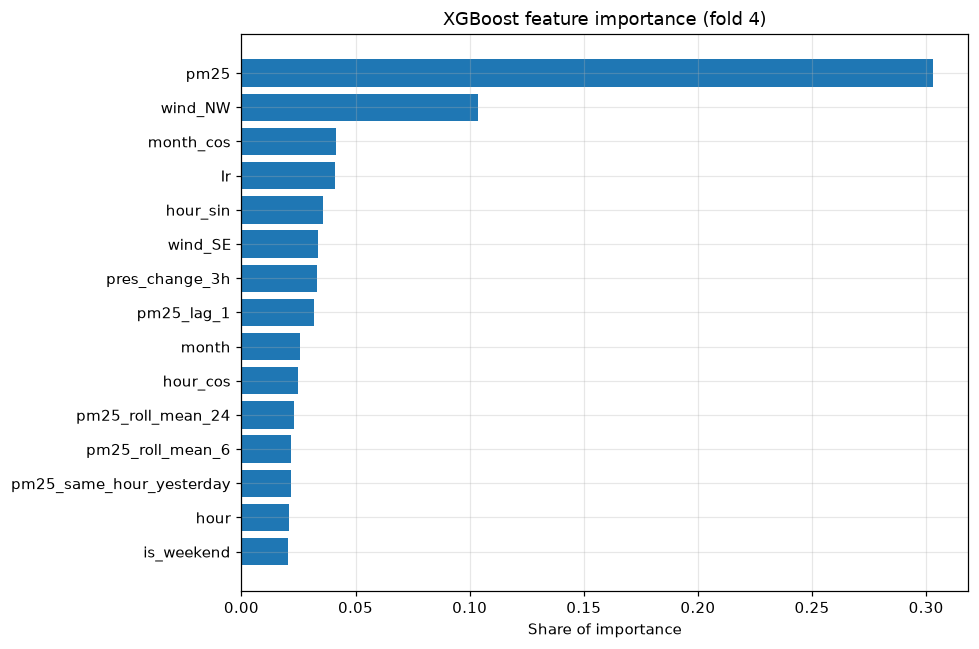

In [3]:
top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["feature"], top["importance"], color="tab:blue")
ax.set_title("XGBoost feature importance (fold 4)")
ax.set_xlabel("Share of importance")
plt.tight_layout()
plt.savefig(f"{FIG}/13_feature_importance.png")
plt.show()

## 2. Importance by feature group

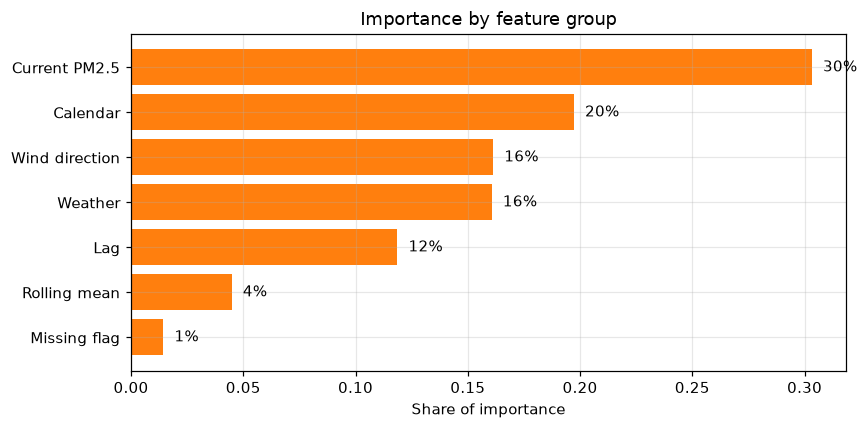

group
Current PM2.5     30.3%
Calendar          19.7%
Wind direction    16.1%
Weather           16.1%
Lag               11.9%
Rolling mean       4.5%
Missing flag       1.4%
Name: importance, dtype: str

In [4]:
by_group = importance.groupby("group")["importance"].sum().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(by_group.index, by_group.values, color="tab:orange")
for i, value in enumerate(by_group.values):
    ax.text(value + 0.005, i, f"{value:.0%}", va="center")
ax.set_title("Importance by feature group")
ax.set_xlabel("Share of importance")
plt.tight_layout()
plt.savefig(f"{FIG}/14_importance_by_group.png")
plt.show()
by_group.sort_values(ascending=False).map("{:.1%}".format)

## Interpretation

- **Current PM2.5** is by far the most important input (about 30%), which matches the strong 6-hour autocorrelation found in EDA.
- **Calendar** features (season and time of day) come second (about 20%), matching the daily and yearly cycles in EDA.
- **Wind direction** and **weather** add about 16% each. The single strongest wind column is northwest wind, which clears the air, exactly as the EDA boxplot showed.
- The hand-picked lag windows carry less weight than expected. Longer or more flexible time patterns may help, which is the gap a sequence model (LSTM) would test next.